Shahlo Solieva

Created 07-07-2026

Updated 07-09-2026 to include scientific notation for totals

Updated 10-20-2026 to include updated FAH sets. 

Use this notebook to create histograms of trajectory lengths from the Folding@home simulations.

In [1]:
# import packages
import numpy as np
import h5py
import matplotlib.pyplot as plt

# adjust BASE_PATH on whether the data is from CH103_mature_VC (not updated) or the rest of the antibodies: 
BASE_PATH = '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_variable_subsample50/data/apo/'
BASE_PATH = '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_variable_subsample50_updated/data/apo/'

# where to save the figures. 
FIGURE_PATH='/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/aggregate_sim_times/figures/'

# helper functions

In [3]:
def get_n_frames(sys_name):
    n_frames = []
    with h5py.File(f'{BASE_PATH}/{sys_name}/cluster-assignments.h5', 'r') as h5_file:
        # iterate through all arrays in the assignments file, get number of frames.
        for traj in range(len(list(h5_file.keys()))):
            dataset_name = list(h5_file.keys())[traj]
            data = h5_file[dataset_name][:]
            n_frames.append(len(data))

    print(sys_name, 'Number of trajectories:',len(n_frames), '| TOTAL ns:',sum(n_frames)*40/1000,'| max ns:',np.max(n_frames)*40/1000)
    return n_frames

def get_n_frames_CAP(sys_name):
    n_frames = []
    with h5py.File(f'{BASE_PATH}/{sys_name}/cluster-assignments-r215.h5', 'r') as h5_file:
        # iterate through all arrays in the assignments file, get number of frames.
        for traj in range(len(list(h5_file.keys()))):
            dataset_name = list(h5_file.keys())[traj]
            data = h5_file[dataset_name][:]
            n_frames.append(len(data))

    print(sys_name, 'Number of trajectories:',len(n_frames), '| TOTAL ns:',sum(n_frames)*40/1000,'| max ns:',np.max(n_frames)*40/1000)
    return n_frames

In [6]:
def sci_notation(number, sig_fig=2):
    ret_string = "{0:.{1:d}e}".format(number, sig_fig)
    a, b = ret_string.split("e")
    b = int(b)
    return a + " * 10^" + str(b)
    
def plot_broken_hist(sys_name, title, n_frames):   
    
    total = sci_notation(sum(n_frames)*40/1000, sig_fig=2)
    avg = sci_notation(np.average(n_frames)*40/1000, sig_fig=2)

    f, (ax, ax2) = plt.subplots(2, 1, sharex=True, gridspec_kw={"height_ratios": [1, 1]}, figsize=[3,1.2])
    custom_bins = np.arange(0,1600,20)
    print(sum(n_frames)*40/1000)
    ax.hist( np.array(n_frames)*40/1000, bins=custom_bins, color='0.5', label=f'Total: {total} ns\nAverage: {avg} ns')
    ax2.hist(np.array(n_frames)*40/1000, bins=custom_bins, color='0.5')
    ax.legend([f'Total: {total} ns\nMean: {avg} ns'], fontsize=6)
    ax.set_ylim(50,1900)  # outliers only
    ax2.set_ylim(0, 50)  # most of the data
    ax.set_yticks([50, 1000, 1900])
    ax2.set_yticks([0,25,50])
    ax.set_xlim(0,1600)
    ax.spines['bottom'].set_visible(False)
    ax2.spines['top'].set_visible(False)
    ax.xaxis.tick_top()
    ax.tick_params(top=False,labeltop=False, labelsize=6)  
    ax2.xaxis.tick_bottom()
    ax2.tick_params(labelsize=6)
    ax.set_title(f'{title}', weight='bold', fontsize=8)
    
    d = .015  # how big to make the diagonal lines in axes coordinates
    kwargs = dict(transform=ax.transAxes, color='k', clip_on=False)
    ax.plot((-d, +d), (-d, +d), **kwargs)        # top-left diagonal
    ax.plot((1 - d, 1 + d), (-d, +d), **kwargs)  # top-right diagonal
    kwargs.update(transform=ax2.transAxes)  # switch to the bottom axes
    ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)  # bottom-left diagonal
    ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)  # bottom-right diagonal
    
    f.supylabel('Number of trajectories', weight='bold',fontsize=6,x=-0.01)
    f.supxlabel('Time (ns)', weight='bold',fontsize=6, y=-0.15)
    f.savefig(f"{FIGURE_PATH}/FAH_trajLengths_{sys_name}.pdf", dpi=300, bbox_inches='tight', transparent=True)
    plt.show()

# Aggregate simulation frames histograms

CAP256_naive_VC Number of trajectories: 1982 | TOTAL ns: 961888.6 | max ns: 755.0
961888.6


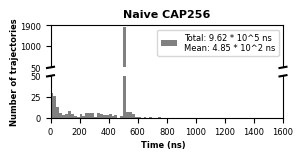

CAP256_mature_VC Number of trajectories: 1985 | TOTAL ns: 1347194.16 | max ns: 724.8
1347194.16


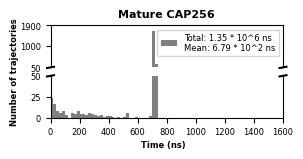

In [10]:
BASE_PATH = '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_variable_subsample50_updated/data/apo/'

n_frames = get_n_frames_CAP('CAP256_naive_VC')
plot_broken_hist('CAP256_naive_VC', 'Naive CAP256', n_frames)

n_frames = get_n_frames_CAP('CAP256_mature_VC')
plot_broken_hist('CAP256_mature_VC', 'Mature CAP256', n_frames)

CH103_naive_VC Number of trajectories: 1989 | TOTAL ns: 1237280.96 | max ns: 1425.0
1237280.96


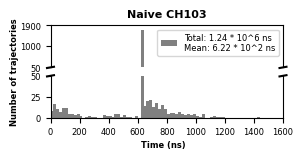

PGT121_naive_VC Number of trajectories: 1994 | TOTAL ns: 398379.44 | max ns: 720.0
398379.44


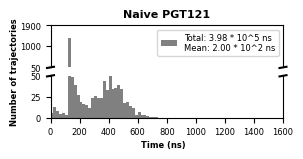

PGT121_mature_VC Number of trajectories: 1989 | TOTAL ns: 1210681.56 | max ns: 1145.0
1210681.56


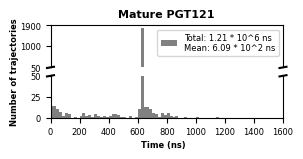

CH65_naive_VC Number of trajectories: 1988 | TOTAL ns: 766925.04 | max ns: 1510.0
766925.04


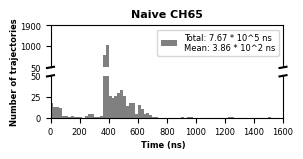

CH65_mature_VC Number of trajectories: 1988 | TOTAL ns: 1286213.8 | max ns: 1550.0
1286213.8


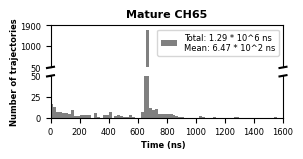

Ab118_naive_VC Number of trajectories: 1986 | TOTAL ns: 1007798.04 | max ns: 1325.0
1007798.04


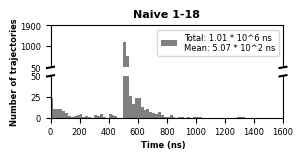

Ab118_mature_VC Number of trajectories: 1989 | TOTAL ns: 762099.64 | max ns: 1300.0
762099.64


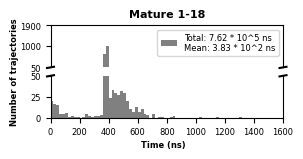

In [9]:
BASE_PATH = '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_variable_subsample50_updated/data/apo/'

sys_names = ['CH103_naive_VC',
             'PGT121_naive_VC','PGT121_mature_VC',
             'CH65_naive_VC','CH65_mature_VC',
             'Ab118_naive_VC', 'Ab118_mature_VC']

titles    = ['Naive CH103',
             'Naive PGT121','Mature PGT121',
             'Naive CH65', 'Mature CH65',
             'Naive 1-18','Mature 1-18']

for sys_name,title in zip(sys_names, titles):
    n_frames = get_n_frames(sys_name)
    plot_broken_hist(sys_name, title, n_frames)

# Total frames in FAH simulations: 

In [18]:
all_frames=[]

BASE_PATH = '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_variable_subsample50/data/apo/'
sys_names =  ['CH103_mature_VC']
for sys_name in sys_names:
    all_frames.append(sum(get_n_frames(sys_name))*40/1000)

BASE_PATH = '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_variable_subsample50_updated/data/apo/'
sys_names =  ['CH103_naive_VC',
             'PGT121_naive_VC','PGT121_mature_VC',
             'CH65_naive_VC','CH65_mature_VC',
             'Ab118_naive_VC','Ab118_mature_VC']
for sys_name in sys_names:
    all_frames.append(sum(get_n_frames(sys_name))*40/1000)
for sys_name in ['CAP256_naive_VC', 'CAP256_mature_VC']:
    all_frames.append(sum(get_n_frames_CAP(sys_name))*40/1000)

CH103_mature_VC Number of trajectories: 1985 | TOTAL ns: 753703.76 | max ns: 1350.0
CH103_naive_VC Number of trajectories: 1989 | TOTAL ns: 1237280.96 | max ns: 1425.0
PGT121_naive_VC Number of trajectories: 1994 | TOTAL ns: 398379.44 | max ns: 720.0
PGT121_mature_VC Number of trajectories: 1989 | TOTAL ns: 1210681.56 | max ns: 1145.0
CH65_naive_VC Number of trajectories: 1988 | TOTAL ns: 766925.04 | max ns: 1510.0
CH65_mature_VC Number of trajectories: 1988 | TOTAL ns: 1286213.8 | max ns: 1550.0
Ab118_naive_VC Number of trajectories: 1986 | TOTAL ns: 1007798.04 | max ns: 1325.0
Ab118_mature_VC Number of trajectories: 1989 | TOTAL ns: 762099.64 | max ns: 1300.0
CAP256_naive_VC Number of trajectories: 1982 | TOTAL ns: 961888.6 | max ns: 755.0
CAP256_mature_VC Number of trajectories: 1985 | TOTAL ns: 1347194.16 | max ns: 724.8


In [21]:
print('total milliseconds in FAH set:', sum(all_frames)/1000/1000, 'ms')

total milliseconds in FAH set: 9.732164999999997 ms
